# 01: Ingest tour
What the warehouse holds, how the polite client behaved, and a six-digit NORAD round trip. Run `uv run kessler ingest` first (or `git worktree add warehouse_repo data`).

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3})
ROOT = Path.cwd().parent
W = ROOT / "warehouse_repo" / "warehouse"
B = ROOT / "build_out"
from kessler.warehouse.db import connect
con = connect(W)

In [2]:
con.sql("SELECT table_name FROM information_schema.tables ORDER BY 1").df()

,table_name
0,f107_live
1,gcat_launches
2,gcat_objects
3,gp_elements
4,gp_first
5,gp_latest
6,ingest_log
7,kp_live
8,reentry_forecasts
9,satcat


In [3]:
pd.DataFrame({t: [con.sql(f'SELECT count(*) FROM {t}').fetchone()[0]] for t in ['gp_elements','satcat','space_weather','gcat_objects','gcat_launches','ingest_log']}).T.rename(columns={0:'rows'})

,rows
gp_elements,16869
satcat,71088
space_weather,25444
gcat_objects,71091
gcat_launches,76005
ingest_log,48


## Every HTTP request is logged
Cache hits make no network call; any non-200 stops the run.

In [4]:
con.sql("SELECT host, status, from_cache, count(*) n, sum(bytes)/1e6 AS MB FROM ingest_log GROUP BY ALL ORDER BY n DESC").df()

,host,status,from_cache,n,MB
0,celestrak,200,False,29,2.505425
1,celestrak,200,True,14,9.617017
2,gcat,200,True,3,33.421020
3,noaa,200,True,2,0.027244


## Six-digit NORAD IDs (TLE cannot encode these)

In [5]:
con.sql("SELECT norad_cat_id, typeof(norad_cat_id) t, object_name, epoch FROM gp_latest WHERE norad_cat_id >= 100000 ORDER BY norad_cat_id LIMIT 10").df()

,norad_cat_id,t,object_name,epoch
0,100083,BIGINT,RASSVET-3 17,2026-10-18 09:00:29.804832-04:00
1,100089,BIGINT,RASSVET-3 23,2026-10-18 08:24:41.645952-04:00
2,100465,BIGINT,OBJECT A,2026-10-18 20:13:00.538464-04:00
3,100466,BIGINT,OBJECT B,2026-10-18 23:25:52.211424-04:00
4,100467,BIGINT,OBJECT C,2026-10-18 21:38:02.566464-04:00
5,100468,BIGINT,OBJECT D,2026-10-19 00:38:18.236832-04:00
6,100469,BIGINT,BY70-4,2026-10-19 00:37:42.031776-04:00
7,100470,BIGINT,JAMX01 (JING'AN DREAM STAR),2026-10-19 00:32:18.557088-04:00
8,100471,BIGINT,OBJECT G,2026-10-18 21:44:43.398528-04:00
9,100472,BIGINT,CZ-6C R/B,2026-10-19 00:21:48.719232-04:00


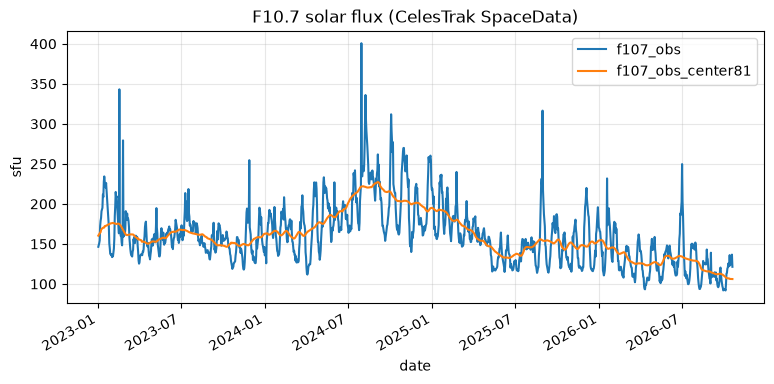

In [6]:
sw = con.sql("SELECT date, f107_obs, f107_obs_center81, kp_max FROM space_weather WHERE date >= DATE '2023-01-01' AND f107_data_type='OBS' ORDER BY date").df()
ax = sw.plot(x='date', y=['f107_obs','f107_obs_center81'], title='F10.7 solar flux (CelesTrak SpaceData)'); ax.set_ylabel('sfu');